# Objectif 

L'objectif est d'étudier le biais en temps observé sur les surfaces d'ambiguïté de l'event (AIS) 3. 

Plusieurs zones d'ombres à étudier :

* Le passage de l'event 3 est-il un passage de l'ATALANTE ce qui expliquerait pourquoi ça marche plutôt bien ? 
* Le biais en temps observé est-il compatible avec un biais dû au bras de levier entre l'antenne AIS et la position effective de la source / l'incertitude sur la répartition des sources sur le navire. 

Date de création 12/11/2026

In [1]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle

from scipy.io import loadmat
from matplotlib.lines import Line2D
from datetime import datetime, timedelta

In [2]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from real_data_analysis.acouplane.src.acouplane_cst import (
    ACOUPLANE_PORTION_NC_ROOT_FPATH,
    ROOT_ACOUPLANE_PROCESSED_IMG_DIR,
    ACOUPLANE_POSITIONS_NC_FPATH,
    AIS_FPATH,
)
from real_data_analysis.acouplane.src.acouplane_combination import (
    RCV_COMBINATION_METHODS,
    combination_intersection_positions,
    enumerate_rcv_combinations,
    format_rcv_combination,
    rcv_combination_records,
)
from real_data_analysis.acouplane.src.acouplane_console import (
    make_figure_saver,
    make_logger,
)
from real_data_analysis.acouplane.src.acouplane_conventions import (
    library_event_error_mode,
)
from real_data_analysis.acouplane.src.acouplane_event import (
    apply_mfp_strategy_to_portions,
    build_portion_library,
    derive_portion_cpsd_welch,
    derive_portion_features,
    get_crossing_distance_m,
)
from real_data_analysis.acouplane.src.acouplane_localization import (
    add_validity_column,
    best_rcv_pair_per_distance,
    pivot_error_summary,
    select_and_order_distance_types,
    summarize_localization_errors,
)
from real_data_analysis.acouplane.src.acouplane_plot_analysis import (
    plot_error_cdf,
    plot_metric_vs_n_rcv,
    plot_rcv_pair_performance_heatmaps,
)
from real_data_analysis.acouplane.src.acouplane_plot_event import (
    plot_event_features,
    plot_library_and_event_map,
)
from real_data_analysis.acouplane.src.acouplane_plot_mfp import (
    ambiguity_figure_filename,
    plot_combined_intersection_ambiguity,
    plot_combined_intersection_gamma_comparison,
    _combined_surfaces_and_positions,
)
from real_data_analysis.acouplane.src.acouplane_plot_portion import (
    plot_portion_tir_pos,
    plot_obs_pos,
)
from real_data_analysis.acouplane.src.acouplane_portion_io import (
    list_stored_intersections,
    open_portion,
    section_name_of,
)

# Chargement des données 

In [3]:
portion_id = 5
portion_fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = xr.open_datatree(portion_fpath, auto_complex=True)
portion

<xarray.DataTree>
Group: /
│   Attributes:
│       portion_filepath:  /home/program/ubf_tools/real_data_analysis/acouplane/d...
├── Group: /position
│   ├── Group: /position/sn0
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2313, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 19kB ...
│   │           atl_lat                 (atl_datetime) float64 19kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 44kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               5
│   │           section_orientation:      South/North
│   │           section_id:               0
│   │           section_label:            sn0
│   │           obs_position:             OBS position corrected using LMS inversion.
│   │           obs_position_filepath:    C:\Users\baptiste.menetrier\Desktop\devPy\phd\r...
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2120, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:1...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T11:1...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 17kB ...
│   │           atl_lat                 (atl_datetime) float64 17kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 45kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 45kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 45kB ...
│   │       Attributes:
│   │           description:              Posi

In [4]:
portion_event_fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}_event_ais.nc"
portion_event = xr.open_datatree(portion_event_fpath, auto_complex=True)
portion_event

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 4)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 32B ...
│   Attributes:
│       box_lon_min:       5.921525852249999
│       box_lon_max:       5.962816177675
│       box_lat_min:       42.992099350699995
│       box_lat_max:       43.0569610299
│       portion_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_dat...
├── Group: /position
│   ├── Group: /position/event_0
│   │       Dimensions:         (datetime: 63)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 504B 2026-02-24T17:26:40 ... 20...
│   │       Data variables:
│   │           lon             (datetime) float64 504B ...
│   │           lat             (datetime) float64 504B ...
│   │           start_datetime  datetime64[ns] 8B ...
│   │           stop_datetime   datetime64[ns] 8B ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 0
│   │           MMSI:                     20
│   ├── Group: /position/event_1
│   │       Dimensions:         (datetime: 127)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 1kB 2026-02-25T16:18:00 ... 202...
│   │       Data variables:
│   │           lon             (datetime) float64 1kB ...
│   │           lat             (datetime) float64 1kB ...
│   │           start_datetime  datetime64[ns] 8B ...
│   │           stop_datetime   datetime64[ns] 8B ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 1
│   │           MMSI:                     21
│   ├── Group: /position/event_2
│   │       Dimensions:         (datetime: 35)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 280B 2026-02-25T21:03:00 ... 20...
│   │       Data variables:
│   │           lon             (datetime) float64 280B ...
│   │           lat             (datetime) float64 280B ...
│   │           start_datetime  datetime64[ns] 8B ...
│   │           stop_datetime   datetime64[ns] 8B ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 2
│   │           MMSI:                     32
│   └── Group: /position/event_3
│           Dimensions:         (datetime: 70)
│           Coordinates:
│             * datetime        (datetime) datetime64[ns] 560B 2026-02-25T16:26:50 ... 20...
│           Data variables:
│               lon             (datetime) float64 560B ...
│               lat             (datetime) float64 560B ...
│               start_datetime  datetime64[ns] 8B ...
│               stop_datetime   datetime64[ns] 8B ...
│           Attributes:
│               description:              Positions AIS interpolées
│               interpolation_time_step:  10s
│               campagne:                 ACOUPLANE
│               geodesic_frame:           WGS84
│               event_id:                 3
│               MMSI:                     41
└── Group: /pressure
    ├── Group: /pressure/event_0
    │       Dimensions:         (time_obs1: 1240001, time_obs2: 1240001,
    │                            time_obs4: 1240001, time_obs5: 1240001,
    │                            time_obs6: 1240001, time_obs7: 1240001, obs_id: 6)
    │       Coordinates:
    │         * time_obs1       (time_obs1) datetime64[ns] 10MB 2026-02-24T17:26:40 ... 2...
    │         * time_

In [5]:
portion_event_fpath_mfp = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}_event_ais_mfp.nc"
portion_ais_mfp = xr.open_datatree(portion_event_fpath_mfp, auto_complex=True)
portion_ais_mfp

<xarray.DataTree>
Group: /
│   Attributes:
│       description:         MFP between a library and events
│       reference_receiver:  obs1
└── Group: /mfp_intersection
    ├── Group: /mfp_intersection/sn0
    │   └── Group: /mfp_intersection/sn0/event_3
    │           Dimensions:                 (rcv_id: 7, library_datetime: 787,
    │                                        event_datetime: 273, rcv_id_feature: 5)
    │           Coordinates:
    │             * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
    │             * library_datetime        (library_datetime) datetime64[ns] 6kB 2026-02-25T...
    │             * event_datetime          (event_datetime) datetime64[ns] 2kB 2026-02-25T16...
    │             * rcv_id_feature          (rcv_id_feature) <U4 80B 'obs2' 'obs4' ... 'obs7'
    │           Data variables: (12/14)
    │               rcv_lon                 (rcv_id) float64 56B ...
    │               rcv_lat                 (rcv_id) float64 56B ...
    │               rcv_immersion           (rcv_id) int16 14B ...
    │               library_lon             (library_datetime) float64 6kB ...
    │               library_lat             (library_datetime) float64 6kB ...
    │               event_lon               (event_datetime) float64 2kB ...
    │               ...                      ...
    │               d_theta                 (rcv_id_feature, library_datetime, event_datetime) float64 9MB ...
    │               d_theta_gamma           (rcv_id_feature, library_datetime, event_datetime) float64 9MB ...
    │               d_L2_gamma              (rcv_id_feature, library_datetime, event_datetime) float64 9MB ...
    │               d_dcf                   (rcv_id_feature, library_datetime, event_datetime) float64 9MB ...
    │               d_theta_gamma_centered  (rcv_id_feature, library_datetime, event_datetime) float64 9MB ...
    │               d_L2_gamma_centered     (rcv_id_feature, library_datetime, event_datetime) float64 9MB ...
    │           Attributes:
    │               description:               MFP result for a library section and an event
    │               campagne:                  ACOUPLANE
    │               section1:                  sn0
    │               section2:                  event_3
    │               library_acquisition_mode:  active
    │               event_acquisition_mode:    passive
    │               reference_receiver:        obs1
    │               obs_position:              OBS position corrected using LMS inversion.
    │               obs_position_filepath:     C:\Users\baptiste.menetrier\Desktop\devPy\phd\...
    ├── Group: /mfp_intersection/sn1
    │   └── Group: /mfp_intersection/sn1/event_3
    │           Dimensions:                 (rcv_id: 7, library_datetime: 796,
    │                                        event_datetime: 273, rcv_id_feature: 5)
    │           Coordinates:
    │             * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
    │             * library_datetime        (library_datetime) datetime64[ns] 6kB 2026-02-25T...
    │             * event_datetime          (event_datetime) datetime64[ns] 2kB 2026-02-25T16...
    │             * rcv_id_feature          (rcv_id_feature) <U4 80B 'obs2' 'obs4' ... 'obs7'
    │           Data variables: (12/14)
    │               rcv_lon                 (rcv_id) float64 56B ...
    │               rcv_lat                 (rcv_id) float64 56B ...
    │               rcv_immersion           (rcv_id) int16 14B ...
    │               library_lon             (library_datetime) float64 6kB ...
    │               library_lat             (library_datetime) float64 6kB ...
    │               event_lon               (event_datetime) float64 2kB ...
    │               ...                      ...
    │               d_theta                 (rcv_id_feature, library_datetime, event_datetime) float64 9MB ...
    │               d_theta_gamma           

# Illustration du biais 

## Une intersection 

### Paramètres 

In [6]:
event = "event_3"
library0 = "sn0"
metric = "theta_gamma_centered"
rcv_combination = ["obs2", "obs4"]
combination_method = "mean_surfaces"
ambiguity_cmap = "Grays_r"
ambiguity_max_quantile = (
    0.95  # quantile of each feature distance used as upper bound of its color scale
)
ambiguity_d_real_vmax = 100  # upper bound of the color scale of the real distance [m]
ambiguity_metrics = ["theta_gamma_centered", "L2_gamma_centered", "dcf"]

### Surface d'ambiguïté 

In [7]:
ds_mfp = portion_ais_mfp.mfp_intersection[library0][event]
library_display_name = f"library {section_name_of(portion.position[library0])}"
event_attrs = portion_event.position[event].to_dataset().attrs
event_display_name = f"event {event_attrs.get('event_id', event)}"
library_display_name, event_display_name

('library South/North 0', 'event 3')

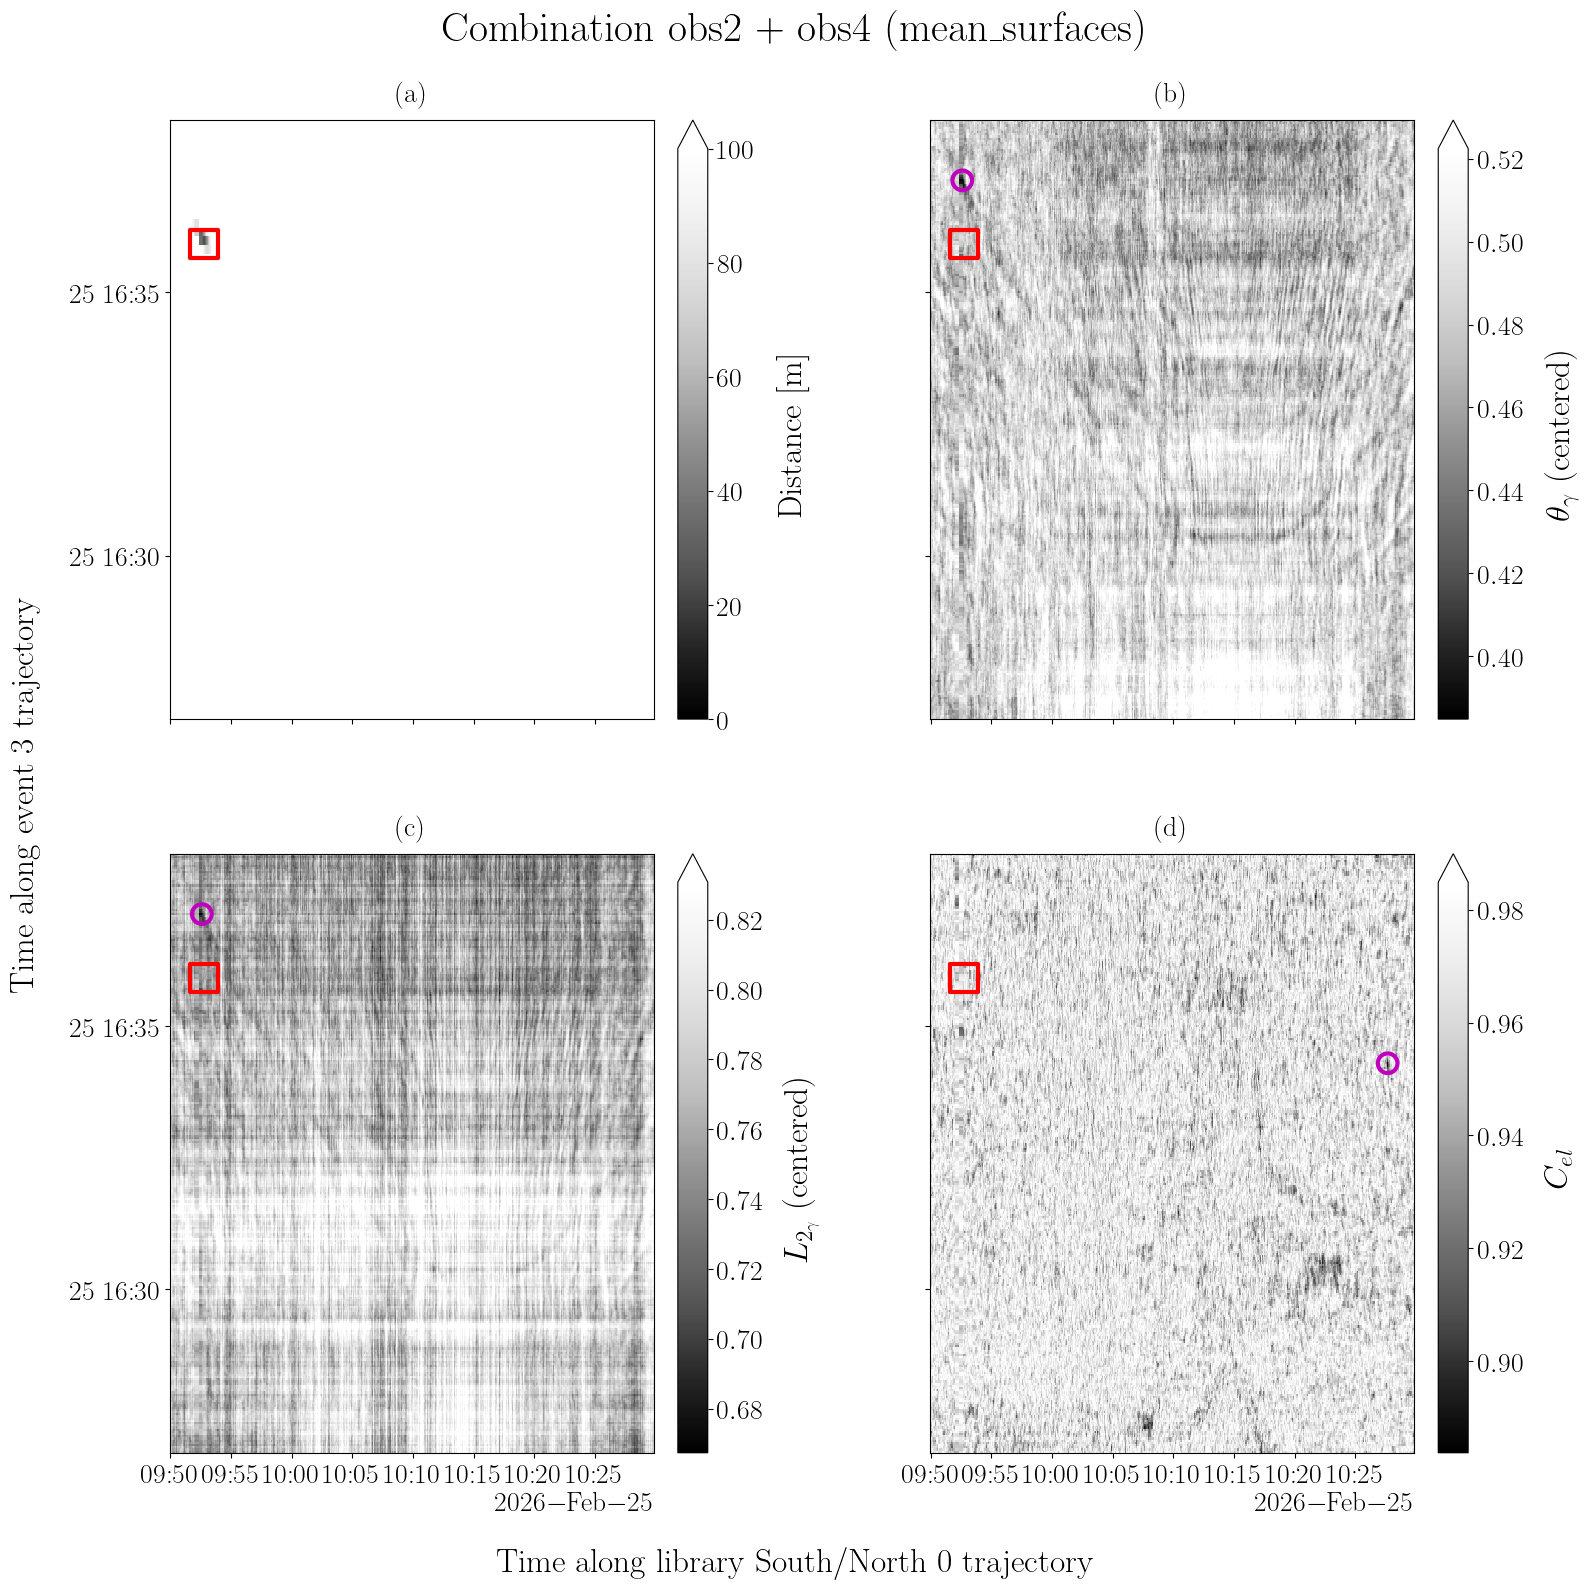

In [8]:
fig = plot_combined_intersection_ambiguity(
    ds_mfp,
    rcv_combination,
    library_display_name,
    event_display_name,
    method=combination_method,
    cmap=ambiguity_cmap,
    max_quantile=ambiguity_max_quantile,
    metrics=ambiguity_metrics,
    d_real_vmax=ambiguity_d_real_vmax,
)

### Biais 

In [9]:
ds_combined, target_dt, guess_dt = _combined_surfaces_and_positions(
    ds_mfp, rcv_combination=rcv_combination, method=combination_method
)
# Target
target_dt_lib, target_dt_event = target_dt 
print(
    f"Target intersection datetime : \n\t Along library {target_dt_lib} \n\t Along event {target_dt_event}"
)
# Guess
guess_dt_lib, guess_dt_event = guess_dt[metric]
print(
    f"Guess intersection datetime : \n\t Along library {guess_dt_lib} \n\t Along event {guess_dt_event}"
)
err_time_along_lib_ns = target_dt_lib - guess_dt_lib
err_time_along_lib_s = err_time_along_lib_ns / np.timedelta64(1, "s")
err_time_along_event_ns = target_dt_event - guess_dt_event
err_time_along_event_s = err_time_along_event_ns / np.timedelta64(1, "s")
print(
    f"Error time along library = {err_time_along_lib_s} s \nError time along event = {err_time_along_event_s}s"
)


Target intersection datetime : 
	 Along library 2026-02-25T09:52:45.600098000 
	 Along event 2026-02-25T16:35:55.000000000
Guess intersection datetime : 
	 Along library 2026-02-25T09:52:36.600098000 
	 Along event 2026-02-25T16:37:07.500000000
Error time along library = 9.0 s 
Error time along event = -72.5s


## L'ensemble des intersections 

### Sélection des sections de la librairie dans l'ordre de croisement avec l'event 3 

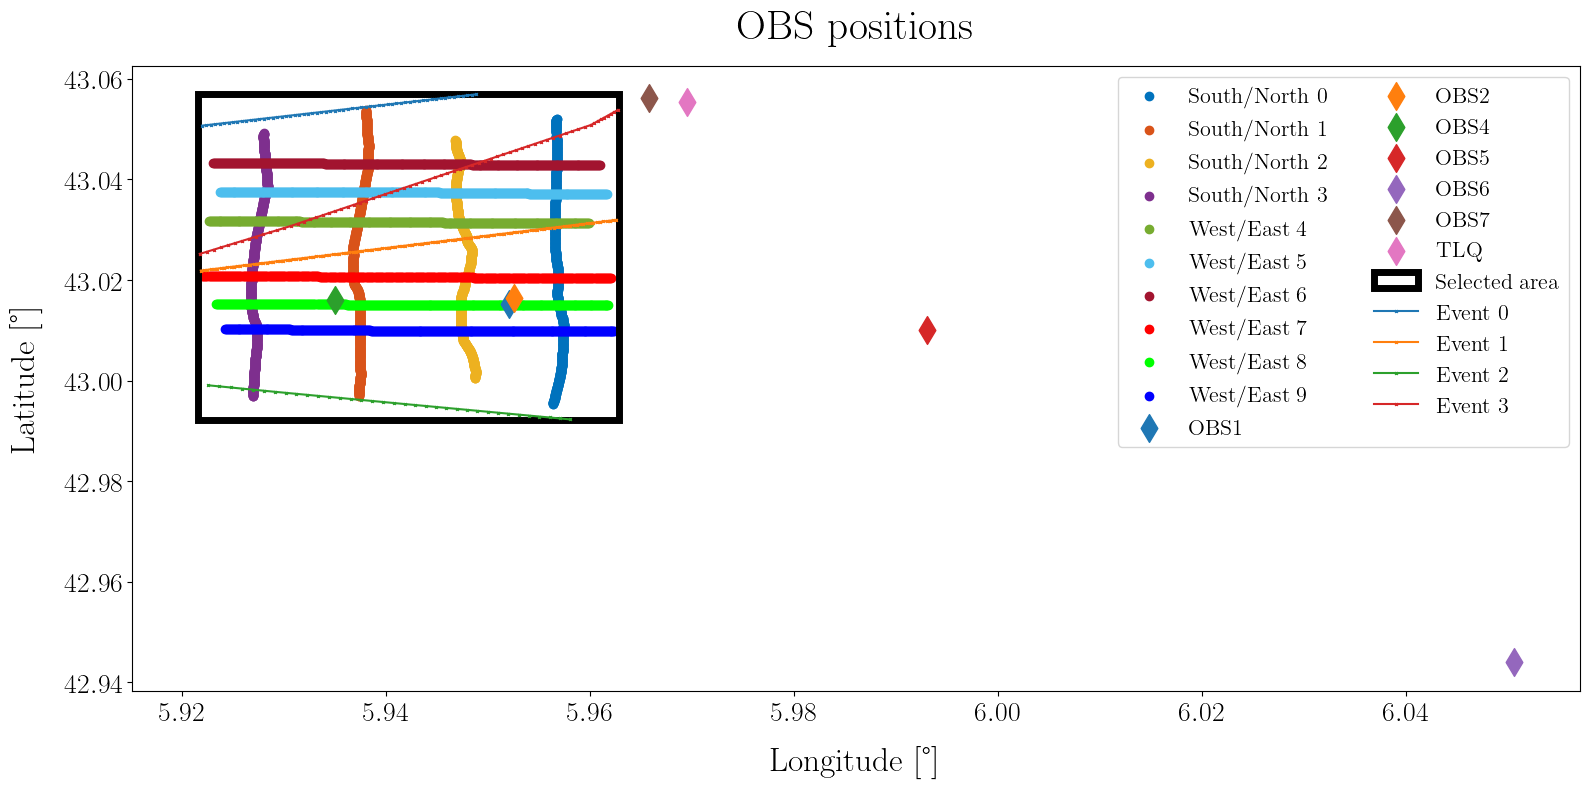

In [10]:
# Plot
fig, ax = plot_portion_tir_pos(portion_tree=portion)
ax.add_patch(
    Rectangle(
        (portion_event.box_lon_min, portion_event.box_lat_min),
        portion_event.box_lon_max - portion_event.box_lon_min,
        portion_event.box_lat_max - portion_event.box_lat_min,
        fc="none",
        ec="k",
        lw=5,
        label="Selected area",
    )
)

for name, node in portion_event.position.children.items():
    ds_position_section = node.to_dataset()
    plt.plot(
        ds_position_section.lon, ds_position_section.lat, "-x", markersize=2, label=f"Event {ds_position_section.event_id}"
    )

ax.legend()
legend = ax.get_legend()

if legend is not None:
    handles = legend.legend_handles
    labels = [text.get_text() for text in legend.get_texts()]

    legend.remove()

    ax.legend(
        handles,
        labels,
        loc="upper right",
        fontsize=16,
        ncols=2,
    )

In [11]:
library_sections = [
    "sn0",
    "oe6",
    "sn2",
    "oe5",
    "sn1",
    "oe4",
    "sn3",
]
n_library = len(library_sections)

### Calcul de l'ensemble des surfaces d'ambiguïté 

In [12]:
# Dedicated arrays (one element per library section)
target_dt_lib_arr = np.full(n_library, np.datetime64("NaT"), dtype="datetime64[ns]")
target_dt_event_arr = np.full(n_library, np.datetime64("NaT"), dtype="datetime64[ns]")
guess_dt_lib_arr = np.full(n_library, np.datetime64("NaT"), dtype="datetime64[ns]")
guess_dt_event_arr = np.full(n_library, np.datetime64("NaT"), dtype="datetime64[ns]")
err_time_along_lib_s_arr = np.full(n_library, np.nan)
err_time_along_event_s_arr = np.full(n_library, np.nan)

# 1) Combine the surfaces of every library section and store the target / guess positions
combined = {}
for il, library in enumerate(library_sections):
    ds_mfp = portion_ais_mfp.mfp_intersection[library][event]
    ds_combined, target_dt, guess_dt = _combined_surfaces_and_positions(
        ds_mfp, rcv_combination=rcv_combination, method=combination_method
    )
    combined[library] = ds_combined

    # Target
    target_dt_lib, target_dt_event = target_dt
    # print(
    #     f"[{library}] Target intersection datetime : \n\t Along library {target_dt_lib} \n\t Along event {target_dt_event}"
    # )
    target_dt_lib_arr[il] = target_dt_lib
    target_dt_event_arr[il] = target_dt_event

    # Guess
    guess_dt_lib, guess_dt_event = guess_dt[metric]
    # print(
    #     f"[{library}] Guess intersection datetime : \n\t Along library {guess_dt_lib} \n\t Along event {guess_dt_event}"
    # )
    guess_dt_lib_arr[il] = guess_dt_lib
    guess_dt_event_arr[il] = guess_dt_event

    err_time_along_lib_ns = target_dt_lib - guess_dt_lib
    err_time_along_lib_s_arr[il] = err_time_along_lib_ns / np.timedelta64(1, "s")
    err_time_along_event_ns = target_dt_event - guess_dt_event
    err_time_along_event_s_arr[il] = err_time_along_event_ns / np.timedelta64(1, "s")

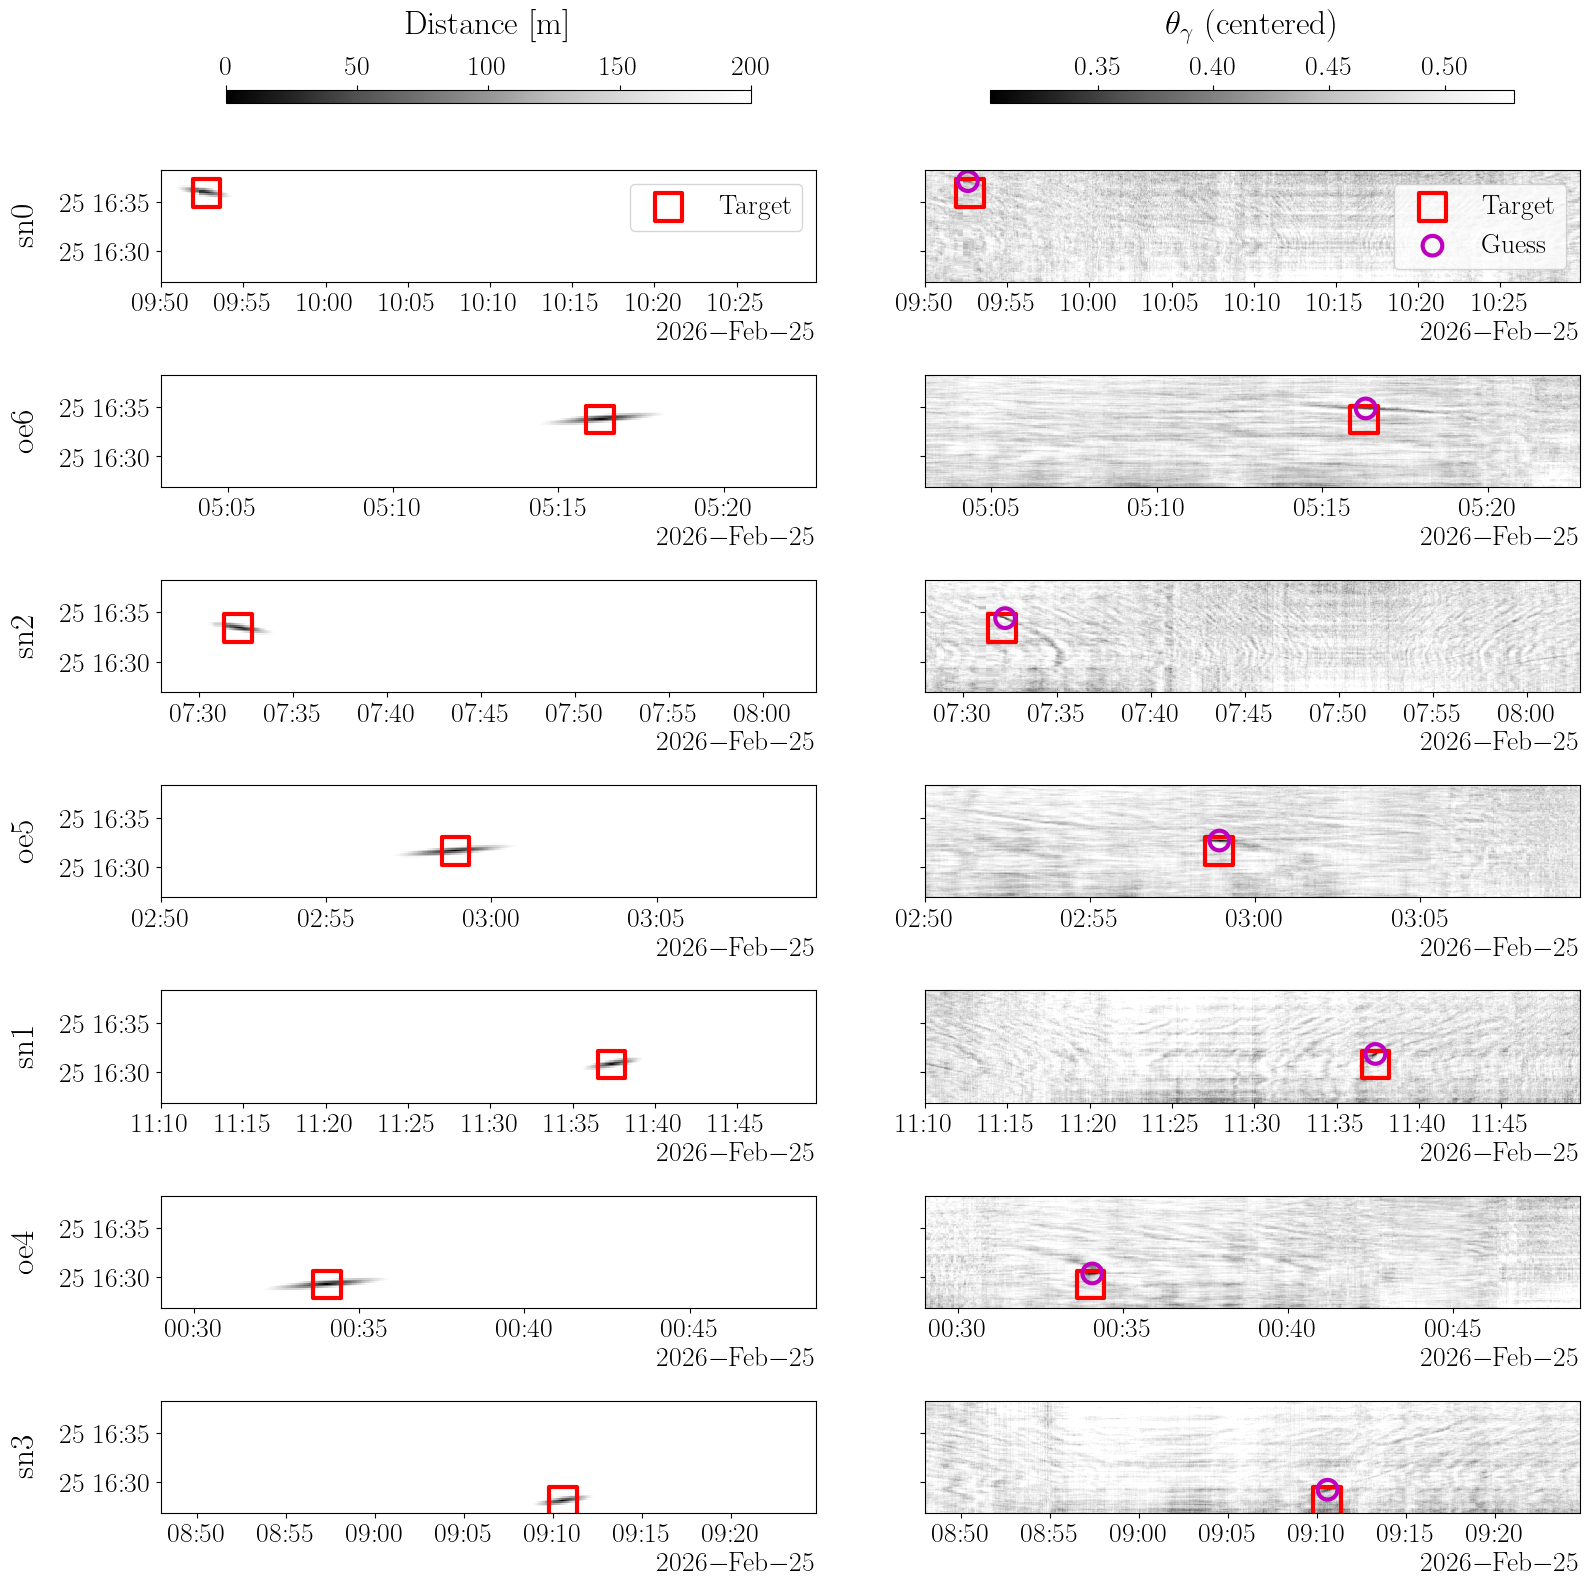

In [13]:
x_dim = "library_datetime"

# 2) Common color scale of the metric column (real distance: fixed scale)
d_real_vmin, d_real_vmax = 0, 200
all_values = np.concatenate(
    [ds[f"d_{metric}"].values.ravel() for ds in combined.values()]
)
all_values = all_values[np.isfinite(all_values)]
metric_vmin = all_values.min()
metric_vmax = np.quantile(all_values, ambiguity_max_quantile)

# 3) Figure: the x axis (library datetimes) differs between sections -> sharex=False
fig, axs = plt.subplots(
    n_library,
    2,
    figsize=(16, 16),
    sharex=False,
    sharey=True,
    layout="constrained",
)
axs = np.atleast_2d(axs)

for il, library in enumerate(library_sections):
    ds_combined = combined[library]

    # add_colorbar=False: a single colorbar per column is added below
    mesh_real = ds_combined.d_real.plot(
        x=x_dim,
        cmap=ambiguity_cmap,
        ax=axs[il, 0],
        vmin=d_real_vmin,
        vmax=d_real_vmax,
        add_colorbar=False,
    )
    mesh_metric = ds_combined[f"d_{metric}"].plot(
        x=x_dim,
        cmap=ambiguity_cmap,
        ax=axs[il, 1],
        vmin=metric_vmin,
        vmax=metric_vmax,
        add_colorbar=False,
    )

    # Target position on both columns (x: along library, y: along event)
    if not np.isnat(target_dt_lib_arr[il]):
        for ax in axs[il]:
            ax.scatter(
                target_dt_lib_arr[il],
                target_dt_event_arr[il],
                marker="s",
                s=400,
                facecolors="none",
                edgecolors="r",
                linewidth=3,
                label="Target",
            )

    # Guess position on the metric column only
    if not np.isnat(guess_dt_lib_arr[il]):
        axs[il, 1].scatter(
            guess_dt_lib_arr[il],
            guess_dt_event_arr[il],
            marker="o",
            s=200,
            facecolors="none",
            edgecolors="m",
            linewidth=3,
            label="Guess",
        )

    # Section name on the left, no titles nor axis labels on the panels
    axs[il, 0].set_ylabel(library)
    axs[il, 1].set_ylabel("")
    for ax in axs[il]:
        ax.set_xlabel("")
        ax.set_title("")

# Legend once (first row)
axs[0, 0].legend(loc="upper right")
axs[0, 1].legend(loc="upper right")


# 4) One horizontal colorbar above each column (label = name and unit of the variable)
def colorbar_label(da):
    label = da.attrs.get("long_name", da.name)
    if "units" in da.attrs:
        label += f" [{da.attrs['units']}]"
    return label


last = combined[library_sections[-1]]
for column, (mesh, da) in enumerate(
    [(mesh_real, last.d_real), (mesh_metric, last[f"d_{metric}"])]
):
    cbar = fig.colorbar(
        mesh,
        ax=axs[:, column],
        location="top",
        orientation="horizontal",
        shrink=0.8,
        aspect=40,
    )
    cbar.set_label(colorbar_label(da))

## Biais observé

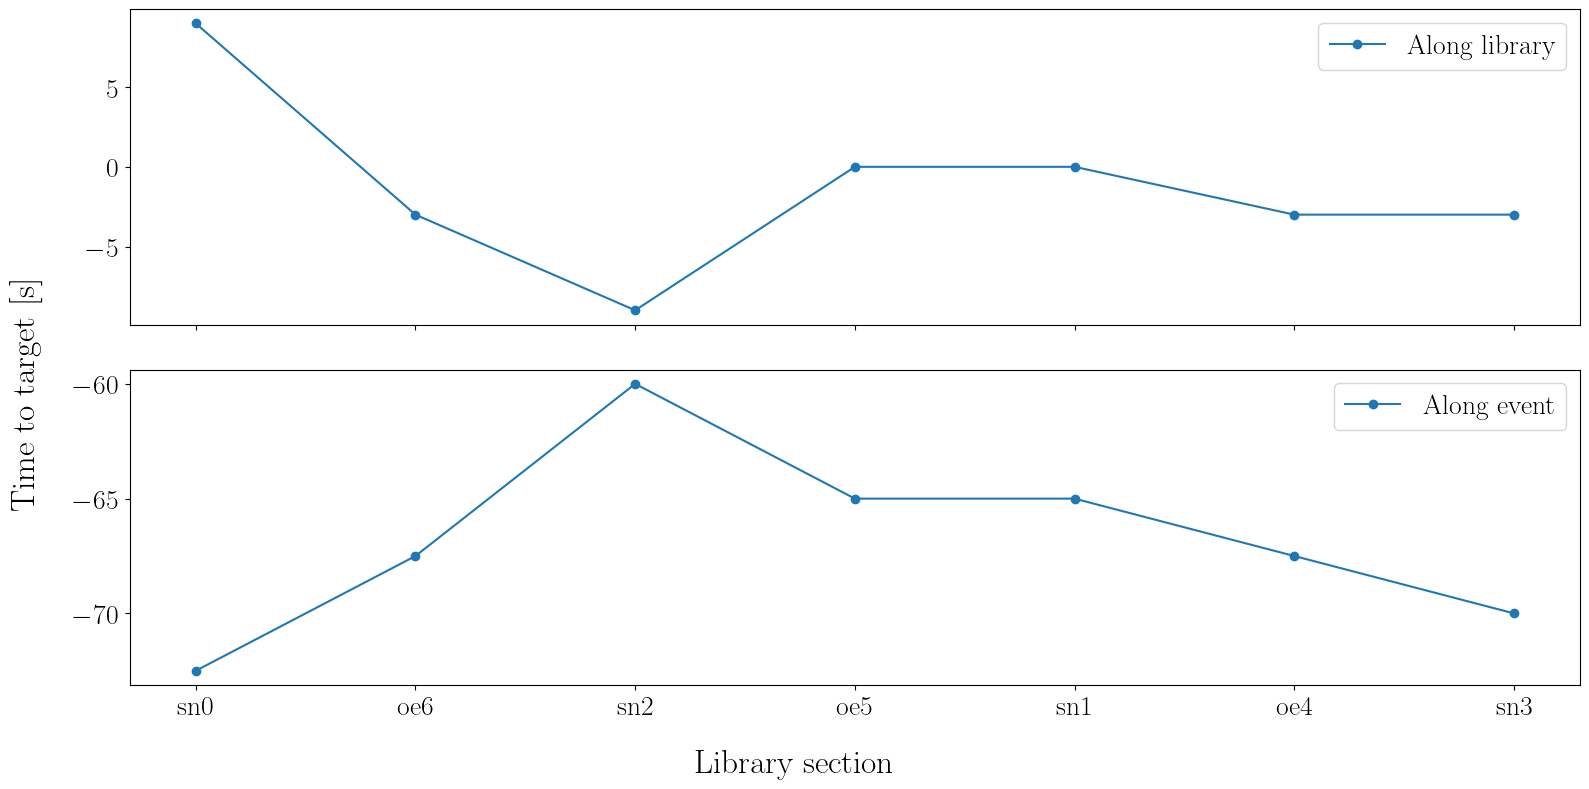

In [14]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
axs[0].plot(library_sections, err_time_along_lib_s_arr, label="Along library", marker="o")
axs[1].plot(library_sections, err_time_along_event_s_arr, label="Along event", marker="o")
fig.supylabel("Time to target [s]")
fig.supxlabel("Library section")
axs[0].legend()
axs[1].legend()

In [15]:
err_time_along_lib_s_mean = np.mean(err_time_along_lib_s_arr)
err_time_along_event_s_mean = np.mean(err_time_along_event_s_arr)
print(f"Mean err along library {err_time_along_lib_s_mean} s")
print(f"Mean err along event {err_time_along_event_s_mean} s")

Mean err along library -1.2857142857142858 s
Mean err along event -66.78571428571429 s


# Vérification position ATL 

On peut vérifier que la source de l'event 3 ne correspond pas à l'ATALANTE en transit dans la zone 

In [16]:
ds_pos_event = portion_event.position[event].to_dataset()
ds_pos_event

<xarray.Dataset> Size: 2kB
Dimensions:         (datetime: 70)
Coordinates:
  * datetime        (datetime) datetime64[ns] 560B 2026-02-25T16:26:50 ... 20...
Data variables:
    lon             (datetime) float64 560B 5.922 5.922 5.923 ... 5.962 5.963
    lat             (datetime) float64 560B 43.03 43.03 43.03 ... 43.05 43.05
    start_datetime  datetime64[ns] 8B ...
    stop_datetime   datetime64[ns] 8B ...
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84
    event_id:                 3
    MMSI:                     41

In [17]:
ds_pos = xr.open_dataset(ACOUPLANE_POSITIONS_NC_FPATH)
ds_pos

<xarray.Dataset> Size: 525MB
Dimensions:         (rcv_id: 7, atl_datetime: 563739, mmsi: 526,
                     ais_datetime: 60447, src_datetime: 33608)
Coordinates:
  * rcv_id          (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
  * atl_datetime    (atl_datetime) datetime64[ns] 5MB 2026-02-24 ... 2026-03-...
  * ais_datetime    (ais_datetime) datetime64[ns] 484kB 2026-02-23T23:59:50 ....
  * src_datetime    (src_datetime) datetime64[ns] 269kB 2026-02-24T20:14:06.6...
Dimensions without coordinates: mmsi
Data variables: (12/13)
    rcv_lon         (rcv_id) float64 56B ...
    rcv_lat         (rcv_id) float64 56B ...
    rcv_immersion   (rcv_id) int16 14B ...
    atl_lon         (atl_datetime) float64 5MB ...
    atl_lat         (atl_datetime) float64 5MB ...
    ais_lon         (mmsi, ais_datetime) float64 254MB ...
    ...              ...
    tir_SEGD        (src_datetime) int64 269kB ...
    tir_ECOS        (src_datetime) int64 269kB ...
    tir_src_lon     (src_datetime) float64 269kB ...
    tir_src_lat     (src_datetime) float64 269kB ...
    tir_vessel_lon  (src_datetime) float64 269kB ...
    tir_vessel_lat  (src_datetime) float64 269kB ...
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84

In [18]:
ds_pos = ds_pos.sel(
    atl_datetime=slice(ds_pos_event.datetime.min(), ds_pos_event.datetime.max())
)
ds_pos = ds_pos.sel(
    src_datetime=slice(ds_pos_event.datetime.min(), ds_pos_event.datetime.max())
)

<Axes: title={'center': 'OBS positions'}, xlabel='Longitude [°]', ylabel='Latitude [°]'>

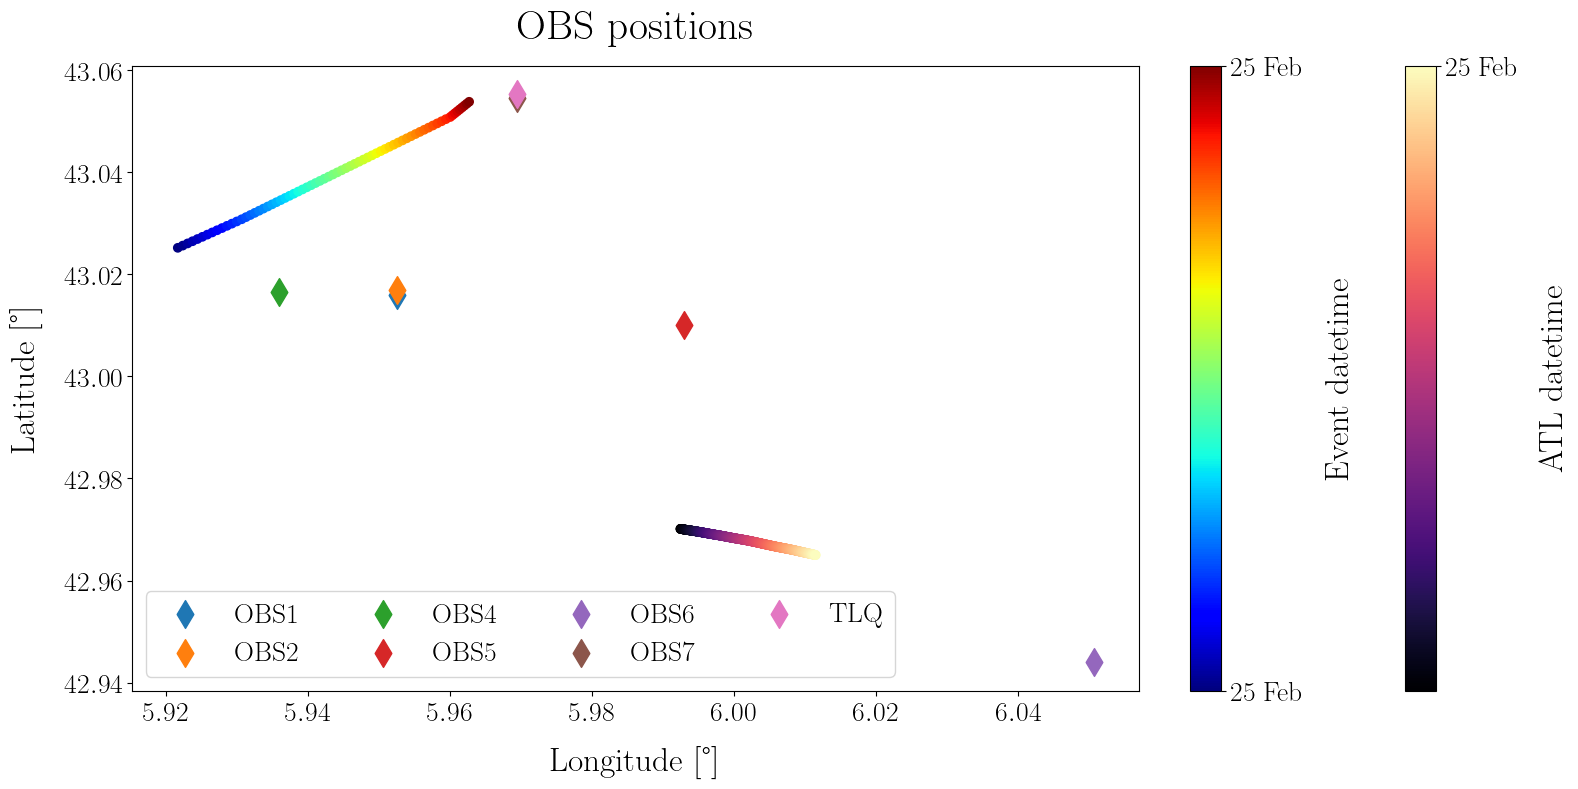

In [19]:
fig, ax = plt.subplots()

dates = ds_pos.atl_datetime.values
date_num = mdates.date2num(dates)

sc = ax.scatter(
    ds_pos.atl_lon,
    ds_pos.atl_lat,
    c=date_num,
    cmap="magma",
)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("ATL datetime")
cbar.ax.yaxis.set_major_locator(mdates.DayLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))


dates = ds_pos_event.datetime.values
date_num = mdates.date2num(dates)

sc = ax.scatter(
    ds_pos_event.lon,
    ds_pos_event.lat,
    c=date_num,
    cmap="jet",
)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Event datetime")
cbar.ax.yaxis.set_major_locator(mdates.DayLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

plot_obs_pos(ds_pos, ax=ax)

# Lien potentiel avec la taille du navire 

Ce biais peut être dû à la taille du navire. Si l'on considère que la source du navire est une source ponctuelle située au niveau de l'hélice du navire, il existe un bras de levier important entre l'antenne AIS du navire généralement situé à l'avant du navire et l'hélice à l'arrière du navire. Pour de gros navires, des portes conteneurs par exemple, ce bras de levier peut être de l'ordre de 100 à 300 voir 400 mètres et pourrait expliquer le biais observé. 

## Vitesse d'avance du navire 

In [20]:
from pyproj import Geod

geod = Geod(ellps="WGS84")

src_lon1, src_lat1 = (
    ds_pos_event.lon,
    ds_pos_event.lat,
)

# Traj 1
lon1_a = src_lon1.values[:-1]
lat1_a = src_lat1.values[:-1]
lon1_b = src_lon1.values[1:]
lat1_b = src_lat1.values[1:]

_, _, dist_11 = geod.inv(lons1=lon1_a, lats1=lat1_a, lons2=lon1_b, lats2=lat1_b)
speed_1 = dist_11 / np.diff(src_lon1.datetime.values).astype("timedelta64[s]").astype(
    float
)

Median speed along event_3 trajectory: 6.81 m/s


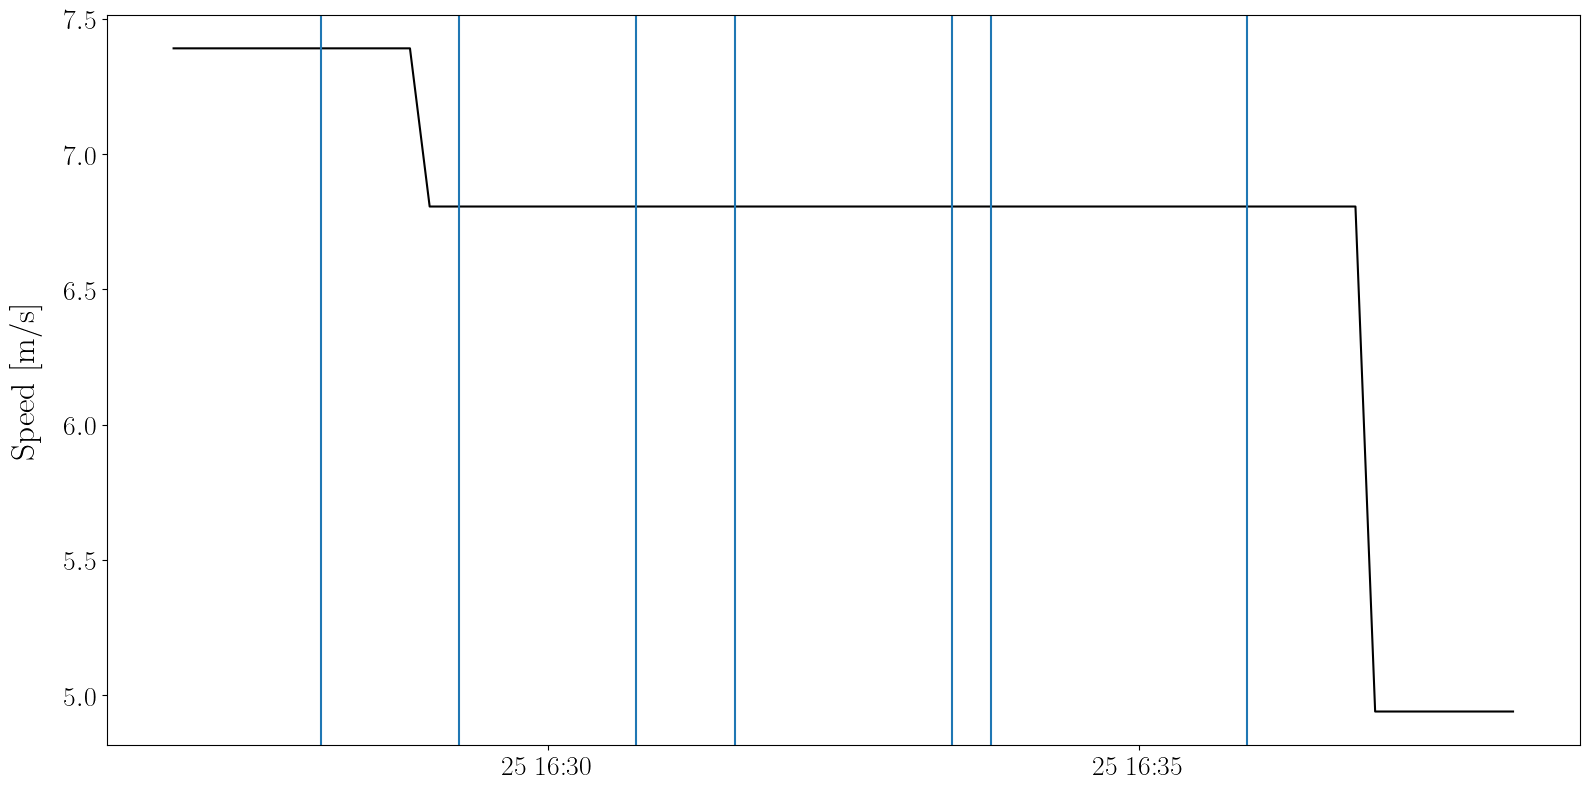

In [21]:
im = plt.plot(src_lon1.datetime[:-1], speed_1, color="k")
plt.ylabel("Speed [m/s]")

Vs = np.nanmedian(speed_1)
print(
    f"Median speed along {event} trajectory: {Vs:.2f} m/s"
)
for dt in target_dt_event_arr:
    plt.axvline(dt)

Connaissant la vitesse d'avance moyenne du navire on peut en déduire l'erreur en distance $\Delta L$ associée à l'erreur $\Delta t$ (le biais) mesurée sur le temps le long de l'event 3 : 

$$
\Delta L = V_s \times \Delta t  
$$





In [22]:
delta_t_ev = err_time_along_event_s_mean
delta_L_ev = Vs * delta_t_ev 
print(f"Delta L (event) = {delta_L_ev} m")

Delta L (event) = -454.5219683691114 m


# Vérification des positions AIS interpolées 

In [23]:
def load_ais():
    df_ais = pd.read_csv(
        AIS_FPATH,
        delimiter=";",
        header=0,
        names=["mmsi", "datetime", "lon", "lat"],
    )
    # Convert datatime columns from str to datetime
    fmt = "%d/%m/%Y %H:%M"
    df_ais["datetime"] = pd.to_datetime(df_ais["datetime"], format=fmt)
    # Change dtypes
    df_ais["mmsi"] = df_ais["mmsi"].astype(int)

    # Remove AIS lines with unique positions (at least two points to define a trajectory)
    df_ais = df_ais.groupby("mmsi").filter(lambda x: len(x) > 1)

    # Remove duplicates if any
    df_ais = df_ais.drop_duplicates()

    # Sort 

    return df_ais

In [24]:
df_ais = load_ais()
df_ais

,mmsi,datetime,lon,lat
0,4,2026-02-27 18:23:00,6.37254,43.13682
1,127,2026-02-24 07:29:00,5.60852,43.17236
2,127,2026-02-24 07:35:00,5.61133,43.17223
3,127,2026-02-24 07:39:00,5.61553,43.16791
4,127,2026-02-24 07:44:00,5.60505,43.15690
...,...,...,...,...
21704,244,2026-03-01 14:45:00,5.74064,43.11501
21705,244,2026-03-01 14:52:00,5.75583,43.12420
21706,244,2026-03-01 14:56:00,5.76034,43.13136
21707,244,2026-03-01 15:05:00,5.76143,43.13110


In [25]:
ds_pos_event

<xarray.Dataset> Size: 2kB
Dimensions:         (datetime: 70)
Coordinates:
  * datetime        (datetime) datetime64[ns] 560B 2026-02-25T16:26:50 ... 20...
Data variables:
    lon             (datetime) float64 560B 5.922 5.922 5.923 ... 5.962 5.963
    lat             (datetime) float64 560B 43.03 43.03 43.03 ... 43.05 43.05
    start_datetime  datetime64[ns] 8B ...
    stop_datetime   datetime64[ns] 8B ...
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84
    event_id:                 3
    MMSI:                     41

In [26]:
import pandas as pd

# Reference datetime
target_datetime = pd.Timestamp(ds_pos_event.datetime.values[0])

# Ensure datetime format
df_ais["datetime"] = pd.to_datetime(df_ais["datetime"])

# Calculate absolute time difference
df_ais["time_diff"] = (df_ais["datetime"] - target_datetime).abs()

# Find the 10 closest distinct MMSI
closest_mmsi = (
    df_ais.sort_values("time_diff")
    .drop_duplicates(subset="mmsi", keep="first")
    .head(10)
    .reset_index(drop=True)
)

print(closest_mmsi[["mmsi", "datetime", "time_diff", "lon", "lat"]])

   mmsi            datetime       time_diff      lon       lat
0    29 2026-02-25 16:28:00 0 days 00:01:10  5.91437  43.11606
1   217 2026-02-25 16:28:00 0 days 00:01:10  5.92453  43.11860
2   376 2026-02-25 16:25:00 0 days 00:01:50  5.61541  43.17445
3   318 2026-02-25 16:25:00 0 days 00:01:50  5.92301  43.10673
4   346 2026-02-25 16:29:00 0 days 00:02:10  5.93071  43.03077
5   313 2026-02-25 16:29:00 0 days 00:02:10  6.37044  43.12336
6   338 2026-02-25 16:29:00 0 days 00:02:10  5.76020  43.12838
7   178 2026-02-25 16:24:00 0 days 00:02:50  6.15897  43.07998
8   151 2026-02-25 16:32:00 0 days 00:05:10  6.15791  43.07029
9   390 2026-02-25 16:21:00 0 days 00:05:50  5.60867  43.16772


In [27]:
# Select raw ais data for event
# df_ais_event = df_ais.loc[df_ais["mmsi"] == ds_pos_event.MMSI]
df_ais_event = df_ais.loc[df_ais["mmsi"] == 346]

# Select period of interest
df_ais_event = df_ais_event.loc[
    (df_ais_event["datetime"] >= ds_pos_event.datetime.min().values)
    & (df_ais_event["datetime"] <= ds_pos_event.datetime.max().values)
]

df_ais_event

,mmsi,datetime,lon,lat,time_diff
11760,346,2026-02-25 16:29:00,5.93071,43.03077,0 days 00:02:10
11761,346,2026-02-25 16:37:00,5.96006,43.05080,0 days 00:10:10


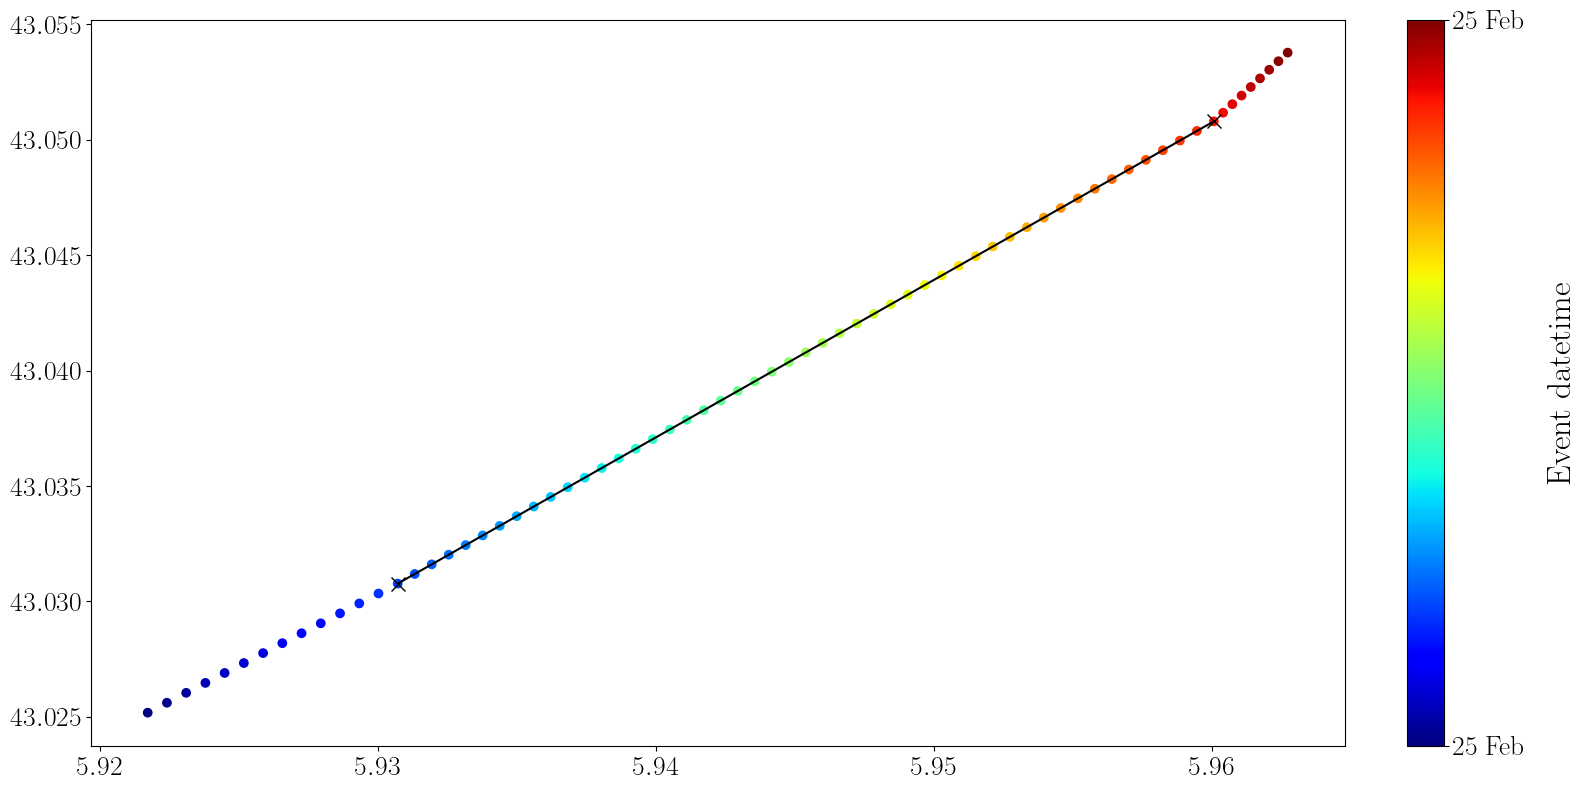

In [28]:
fig, ax = plt.subplots()

dates = df_ais_event.datetime.values
date_num = mdates.date2num(dates)

ax.plot(
    df_ais_event.lon,
    df_ais_event.lat,
    marker="x",
    color="k",
    markersize=10,
    # c=date_num,
    # cmap="magma",
)

dates = ds_pos_event.datetime.values
date_num = mdates.date2num(dates)

sc = ax.scatter(
    ds_pos_event.lon,
    ds_pos_event.lat,
    c=date_num,
    cmap="jet",
)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Event datetime")
cbar.ax.yaxis.set_major_locator(mdates.DayLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

# plot_obs_pos(ds_pos, ax=ax)

Text(0.5, 0.01, 'Time')

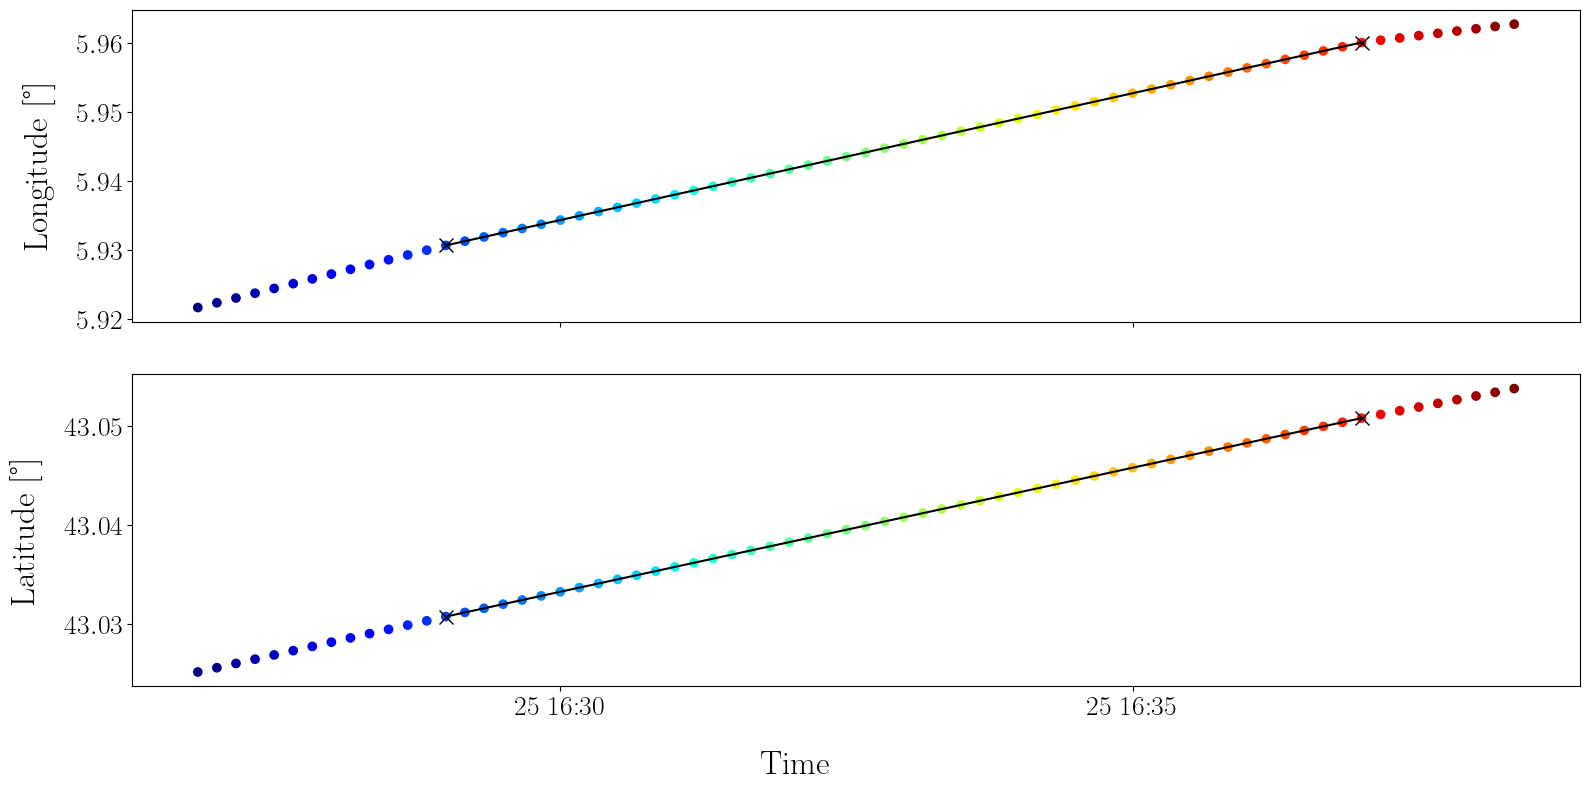

In [29]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

axs[0].plot(
    df_ais_event.datetime,
    df_ais_event.lon,
    # df_ais_event.lat,
    marker="x",
    color="k",
    markersize=10,
    # c=date_num,
    # cmap="magma",
)
axs[0].scatter(
    ds_pos_event.datetime,
    ds_pos_event.lon,
    # ds_pos_event.lat,
    c=date_num,
    cmap="jet",
)
axs[1].plot(
    df_ais_event.datetime,
    # df_ais_event.lon,
    df_ais_event.lat,
    marker="x",
    color="k",
    markersize=10,
    # c=date_num,
    # cmap="magma",
)
axs[1].scatter(
    ds_pos_event.datetime,
    # ds_pos_event.lon,
    ds_pos_event.lat,
    c=date_num,
    cmap="jet",
)
axs[0].set_ylabel("Longitude [°]")
axs[1].set_ylabel("Latitude [°]")

fig.supxlabel("Time")

In [36]:
ds_pos_event.lat.drop_duplicates(dim="datetime")

<xarray.DataArray 'lat' (datetime: 70)> Size: 560B
array([43.025178, 43.025608, 43.026038, 43.026468, 43.026898, 43.027329,
       43.027759, 43.028189, 43.028619, 43.029049, 43.02948 , 43.02991 ,
       43.03034 , 43.03077 , 43.031187, 43.031605, 43.032022, 43.032439,
       43.032857, 43.033274, 43.033692, 43.034109, 43.034526, 43.034944,
       43.035361, 43.035778, 43.036196, 43.036613, 43.03703 , 43.037448,
       43.037865, 43.038282, 43.038699, 43.039117, 43.039534, 43.039951,
       43.040369, 43.040786, 43.041203, 43.041621, 43.042038, 43.042455,
       43.042872, 43.04329 , 43.043707, 43.044124, 43.044541, 43.044959,
       43.045376, 43.045793, 43.04621 , 43.046628, 43.047045, 43.047462,
       43.047879, 43.048297, 43.048714, 43.049131, 43.049548, 43.049966,
       43.050383, 43.0508  , 43.051172, 43.051544, 43.051917, 43.052289,
       43.052661, 43.053033, 43.053406, 43.053778])
Coordinates:
  * datetime  (datetime) datetime64[ns] 560B 2026-02-25T16:26:50 ... 2026-02-...
Attributes:
    units:      °
    long_name:  Latitude